### Analysing census population data

### Author: John Crumlish

# Part 1

In [1]:
import pandas as pd

In [2]:
# Load the 2022 Irish census population data
url = "https://ws.cso.ie/public/api.restful/PxStat.Data.Cube_API.ReadDataset/FY006A/CSV/1.0/en"

df = pd.read_csv(url)

df.tail(3)

,STATISTIC,Statistic Label,TLIST(A1),CensusYear,C02199V02655,Sex,C02076V03371,Single Year of Age,C03789V04537,Administrative Counties,UNIT,VALUE
9789,FY006AC01,Population,2022,2022,2,Female,650,100 years and over,2ae19629-149d-13a3-e055-000000000001,Cavan County Council,Number,12
9790,FY006AC01,Population,2022,2022,2,Female,650,100 years and over,2ae19629-14a4-13a3-e055-000000000001,Donegal County Council,Number,31
9791,FY006AC01,Population,2022,2022,2,Female,650,100 years and over,2ae19629-1495-13a3-e055-000000000001,Monaghan County Council,Number,7


In [3]:
# Keep only the male and female population data
df = df[df["Sex"] != "Both sexes"]

df.tail(3)

,STATISTIC,Statistic Label,TLIST(A1),CensusYear,C02199V02655,Sex,C02076V03371,Single Year of Age,C03789V04537,Administrative Counties,UNIT,VALUE
9789,FY006AC01,Population,2022,2022,2,Female,650,100 years and over,2ae19629-149d-13a3-e055-000000000001,Cavan County Council,Number,12
9790,FY006AC01,Population,2022,2022,2,Female,650,100 years and over,2ae19629-14a4-13a3-e055-000000000001,Donegal County Council,Number,31
9791,FY006AC01,Population,2022,2022,2,Female,650,100 years and over,2ae19629-1495-13a3-e055-000000000001,Monaghan County Council,Number,7


In [4]:
# Keep only the population figures for Ireland
df = df[df["Administrative Counties"] == "Ireland"]

df.tail(3)

,STATISTIC,Statistic Label,TLIST(A1),CensusYear,C02199V02655,Sex,C02076V03371,Single Year of Age,C03789V04537,Administrative Counties,UNIT,VALUE
9696,FY006AC01,Population,2022,2022,2,Female,098,98 years,IE0,Ireland,Number,492
9728,FY006AC01,Population,2022,2022,2,Female,099,99 years,IE0,Ireland,Number,336
9760,FY006AC01,Population,2022,2022,2,Female,650,100 years and over,IE0,Ireland,Number,584


In [5]:
# Get the column headings as a list
headers = df.columns.tolist()

headers

['STATISTIC',
 'Statistic Label',
 'TLIST(A1)',
 'CensusYear',
 'C02199V02655',
 'Sex',
 'C02076V03371',
 'Single Year of Age',
 'C03789V04537',
 'Administrative Counties',
 'UNIT',
 'VALUE']

In [ ]:
# Remove columns not needed for the analysis
drop_col_list = ['STATISTIC', 'Statistic Label', 'TLIST(A1)',
                 'CensusYear', 'C02199V02655', 'C02076V03371',
                 'C03789V04537', 'UNIT']

df.drop(columns=drop_col_list, inplace=True)

# Remove the total population rows
df = df[df["Single Year of Age"] != "All ages"]

# Replace age descriptions with numbers
df['Single Year of Age'] = df['Single Year of Age'].str.replace('Under 1 year', '0')
df['Single Year of Age'] = df['Single Year of Age'].str.replace(r'\D', '', regex=True)

# Convert age and population to integers
df['Single Year of Age'] = df['Single Year of Age'].astype('int64')
df['VALUE'] = df['VALUE'].astype('int64')

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 202 entries, 3296 to 9760
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Sex                      202 non-null    object
 1   Single Year of Age       202 non-null    int64 
 2   Administrative Counties  202 non-null    object
 3   VALUE                    202 non-null    int64 
dtypes: int64(2), object(2)
memory usage: 7.9+ KB


In [7]:
# Create a pivot table to compare male and female populations by age
df_anal = pd.pivot_table(df, values='VALUE', index='Single Year of Age', columns='Sex')

print(df_anal.head(3))

Sex                  Female     Male
Single Year of Age                  
0                   28186.0  29610.0
1                   27545.0  28875.0
2                   28974.0  30236.0


In [ ]:
# Get the column headings
headers = list(df_anal.columns)

sex = headers[0]

sex

'Female'

In [9]:
# Calculate the total population for the selected sex
number_people = df_anal[sex].sum()

number_people

np.float64(2604590.0)

In [10]:
# Multiply each age by the population and add the results
cumages = df_anal[sex].mul(df_anal.index, axis=0).sum()

cumages

np.float64(101422203.0)

In [11]:
# Calculate the weighted mean age
weighted_mean = cumages / number_people

weighted_mean

np.float64(38.9397958987787)

In [12]:
# Select the male population
sex = headers[1]

sex

'Male'

In [13]:
# Calculate the total male population
number_people = df_anal[sex].sum()

number_people

np.float64(2544549.0)

In [14]:
# Multiply each age by the population and add the results
cumages = df_anal[sex].mul(df_anal.index, axis=0).sum()

cumages

np.float64(96029874.0)

In [15]:
# Calculate the weighted mean age
weighted_mean = cumages / number_people

weighted_mean

np.float64(37.7394477371039)

In [16]:
# Calculate the population difference between females and males at each age
df_anal["Difference"] = df_anal["Female"] - df_anal["Male"]

df_anal.head(10)

Sex,Female,Male,Difference
Single Year of Age,,,
0,28186.0,29610.0,-1424.0
1,27545.0,28875.0,-1330.0
2,28974.0,30236.0,-1262.0
3,29483.0,31001.0,-1518.0
4,29819.0,31686.0,-1867.0
5,31342.0,32684.0,-1342.0
6,32622.0,34092.0,-1470.0
7,33572.0,35429.0,-1857.0
8,34437.0,36296.0,-1859.0


<Axes: title={'center': 'Population Difference by Age in Ireland'}, xlabel='Age', ylabel='Female Population - Male Population'>

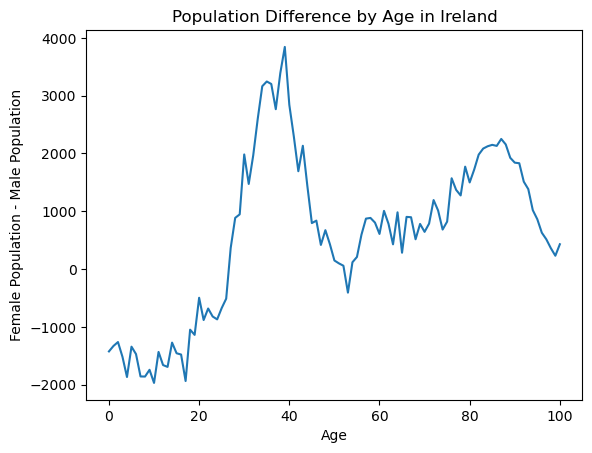

In [17]:
# Plot the population difference between females and males by age
df_anal["Difference"].plot(
    title="Population Difference by Age in Ireland",
    xlabel="Age",
    ylabel="Female Population - Male Population"
)

# Part 2

In [18]:
# Store the age to analyse
age = 35

age

35

In [19]:
# Group people aged between 30 and 40
age_group = df_anal.loc[age - 5 : age + 5]

age_group

Sex,Female,Male,Difference
Single Year of Age,,,
30,32841.0,30858.0,1983.0
31,33710.0,32237.0,1473.0
32,34382.0,32413.0,1969.0
33,34489.0,31888.0,2601.0
34,36284.0,33121.0,3163.0
35,37940.0,34695.0,3245.0
36,39030.0,35828.0,3202.0
37,39193.0,36427.0,2766.0
38,40902.0,37513.0,3389.0


In [20]:
# Calculate the population difference within the age group
female_population = age_group["Female"].sum()
male_population = age_group["Male"].sum()

difference = female_population - male_population

print("Female population:", female_population)
print("Male population:", male_population)
print("Population difference:", difference)

Female population: 414506.0
Male population: 384030.0
Population difference: 30476.0


# Part 3